In [2]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [5]:
model = pd.read_csv("models_constrained.csv")

In [6]:
PN = pd.read_csv("PN_CAT.csv")
CAT = pd.read_csv("all_regions_labeled.csv")
HII = CAT[CAT["simple_class"]=="HII"]
DIG = CAT[CAT["simple_class"]=="DIG"]
SNR = CAT[CAT["simple_class"]=="SNR"]

In [8]:
path = "ADP.2025-07-06T07_52_11.876.fits"
with fits.open(path) as hdul:
    ha = hdul["HA6562_FLUX"].data
    hb = hdul["HB4861_FLUX"].data
    oiii = hdul["OIII5006_FLUX"].data
    nii = hdul["NII6583_FLUX"].data
    sii6717 = hdul["SII6716_FLUX"].data
    sii6731 = hdul["SII6730_FLUX"].data

    ha_err = hdul["HA6562_FLUX_ERR"].data
    hb_err = hdul["HB4861_FLUX_ERR"].data
    oiii_err = hdul["OIII5006_FLUX_ERR"].data
    nii_err = hdul["NII6583_FLUX_ERR"].data
    sii6717_err = hdul["SII6716_FLUX_ERR"].data
    sii6731_err = hdul["SII6730_FLUX_ERR"].data
sii = sii6717 + sii6731
sii_err = np.sqrt(sii6717_err**2 + sii6731_err**2)

snr_ha = ha / ha_err
snr_hb = hb / hb_err
snr_oiii = oiii / oiii_err
snr_nii = nii / nii_err
snr_sii = sii / sii_err
mask = (np.isfinite(ha) & np.isfinite(hb) & np.isfinite(oiii) & np.isfinite(nii) & np.isfinite(sii) &
    (ha > 0) & (hb > 0) & (oiii > 0) & (nii > 0) & (sii > 0) &
    (snr_ha > 3) &(snr_hb > 3) &(snr_oiii > 3) &(snr_nii > 3) &(snr_sii > 3))

x_nii = np.log10(nii[mask] / ha[mask])
x_sii = np.log10(sii[mask] / ha[mask])
y_oiii = np.log10(oiii[mask] / hb[mask])

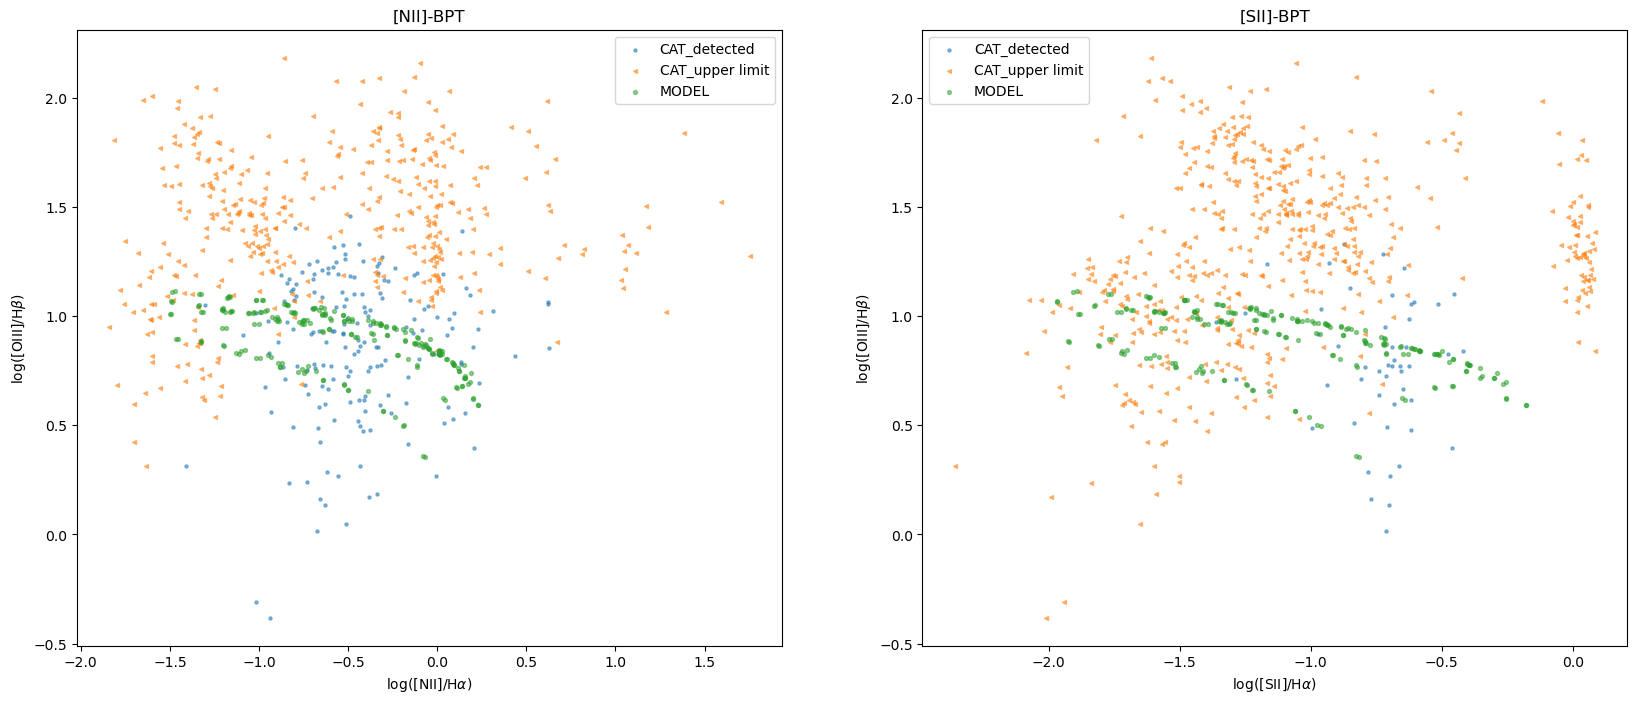

In [9]:
plt.figure(figsize=(20, 8))

# NII BPT
plt.subplot(1, 2, 1)
plt.scatter(PN[PN["use_NII"]]["log_NII_Ha"], PN[PN["use_NII"]]["log_OIII_Hb"], s=5, alpha=0.5, label="CAT_detected")
plt.scatter(PN[~PN["use_NII"]]["log_NII_Ha"], PN[~PN["use_NII"]]["log_OIII_Hb"], s=8, alpha=0.5, marker="<", label="CAT_upper limit")
sub = model[model["class"] == "PN"]
plt.scatter(sub["log_NII_Ha"],sub["log_OIII_Hb"],s=8,alpha=0.5, label='MODEL')
#plt.scatter(x_nii, y_oiii, label="NGC253", s=5, alpha=0.4)
plt.xlabel(r"log([NII]/H$\alpha$)")
plt.ylabel(r"log([OIII]/H$\beta$)")
plt.title("[NII]-BPT")
plt.legend()

# SII BPT
plt.subplot(1, 2, 2)
plt.scatter(PN[PN["use_SII"]]["log_SII_Ha"], PN[PN["use_SII"]]["log_OIII_Hb"], s=5, alpha=0.5, label="CAT_detected")
plt.scatter(PN[~PN["use_SII"]]["log_SII_Ha"], PN[~PN["use_SII"]]["log_OIII_Hb"], s=8, alpha=0.5, marker="<", label="CAT_upper limit")
plt.scatter(sub["log_SII_Ha"],sub["log_OIII_Hb"],s=8,alpha=0.5, label='MODEL')
#plt.scatter(x_sii, y_oiii, label="NGC253", s=5, alpha=0.4)
plt.xlabel(r"log([SII]/H$\alpha$)")
plt.ylabel(r"log([OIII]/H$\beta$)")
plt.title("[SII]-BPT")
plt.legend()
plt.show()

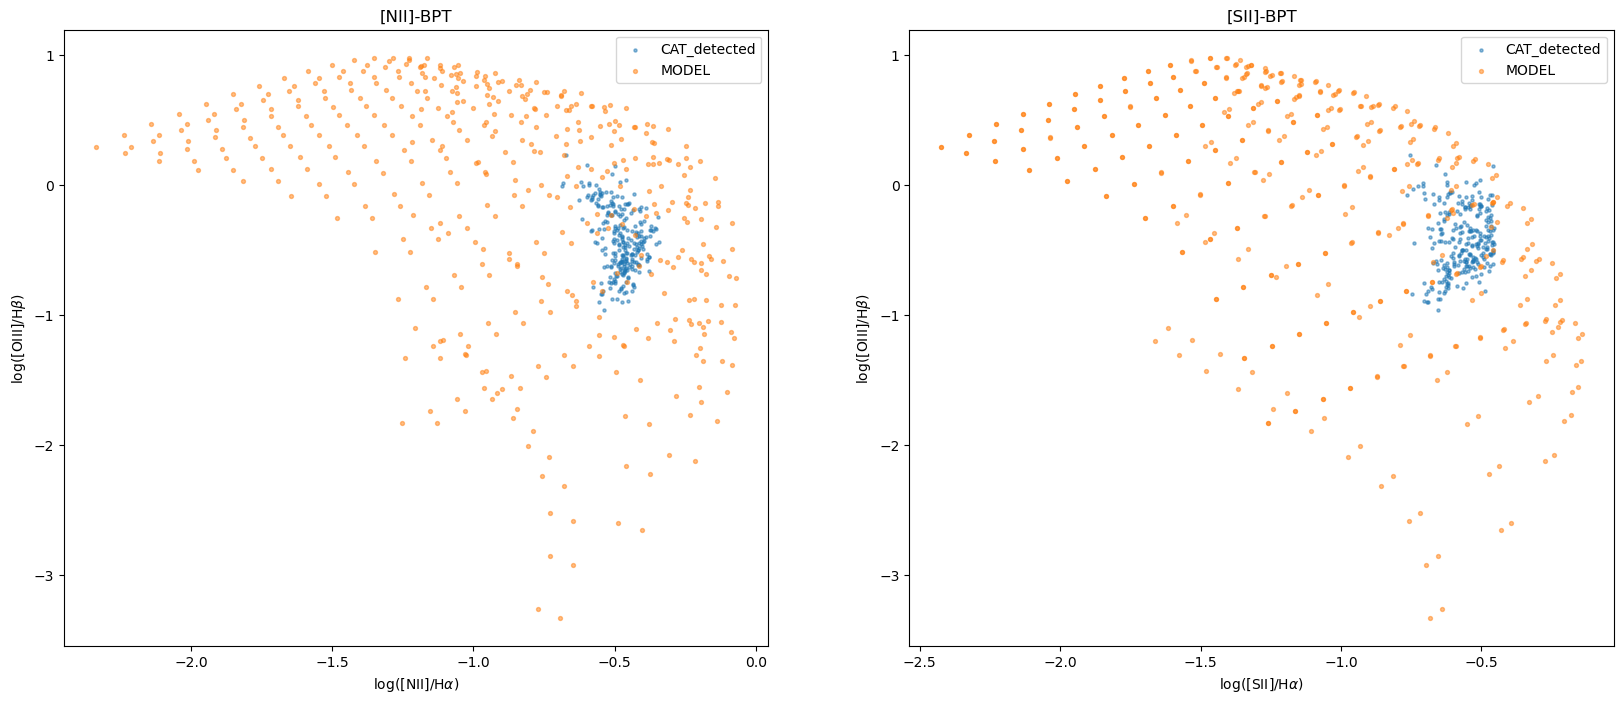

In [12]:
plt.figure(figsize=(20, 8))

# NII BPT
plt.subplot(1, 2, 1)
plt.scatter(HII["log_nii_ha"], HII["log_oiii_hb"], s=5, alpha=0.5, label="CAT_detected")
sub = model[model["class"] == "HII"]
plt.scatter(sub["log_NII_Ha"],sub["log_OIII_Hb"],s=8,alpha=0.5, label='MODEL')
#plt.scatter(x_nii, y_oiii, label="NGC253", s=5, alpha=0.4)
plt.xlabel(r"log([NII]/H$\alpha$)")
plt.ylabel(r"log([OIII]/H$\beta$)")
plt.title("[NII]-BPT")
plt.legend()

# SII BPT
plt.subplot(1, 2, 2)
plt.scatter(HII["log_sii_ha"], HII["log_oiii_hb"], s=5, alpha=0.5, label="CAT_detected")
plt.scatter(sub["log_SII_Ha"],sub["log_OIII_Hb"],s=8,alpha=0.5, label='MODEL')
#plt.scatter(x_sii, y_oiii, label="NGC253", s=5, alpha=0.4)
plt.xlabel(r"log([SII]/H$\alpha$)")
plt.ylabel(r"log([OIII]/H$\beta$)")
plt.title("[SII]-BPT")
plt.legend()
plt.show()

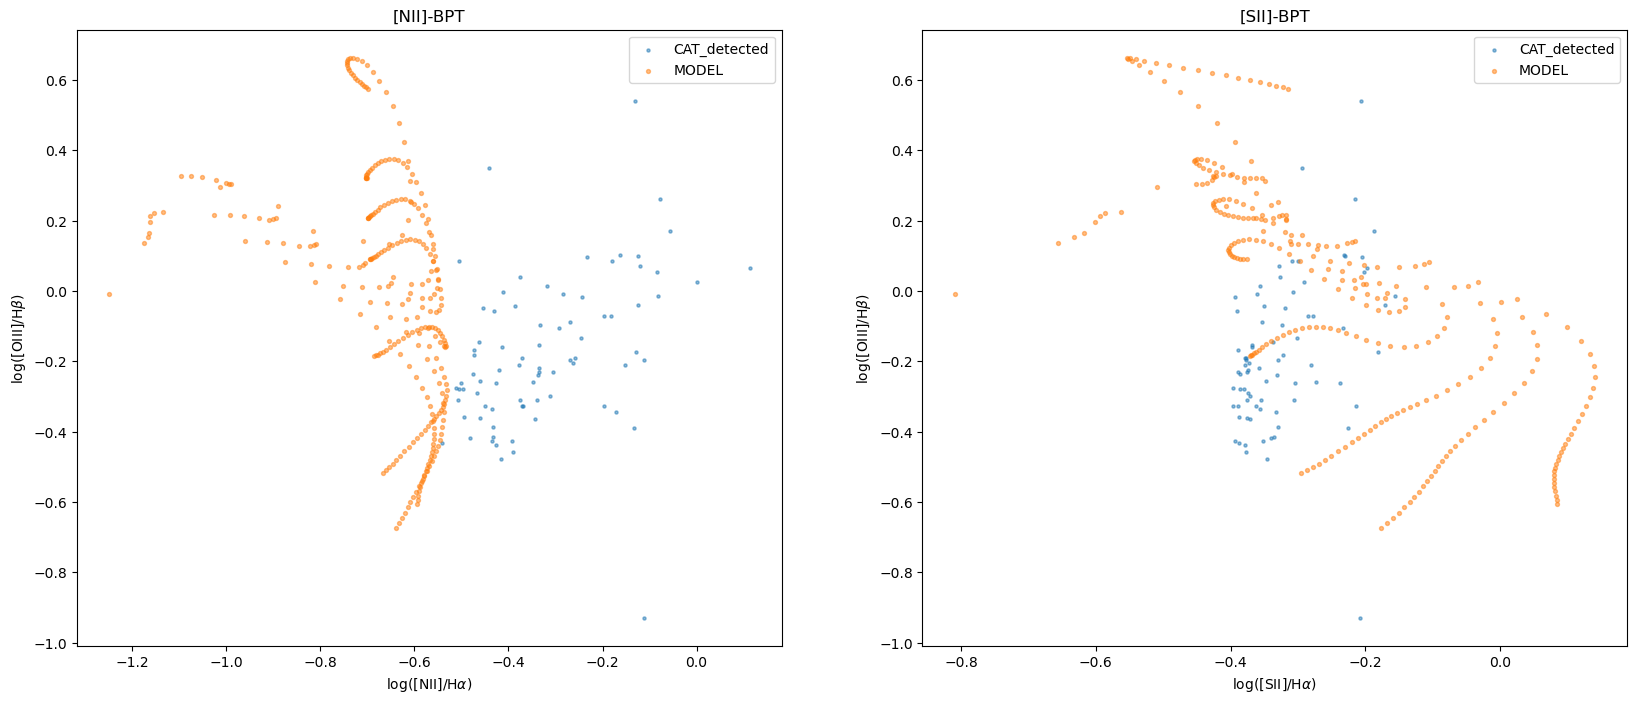

In [13]:
plt.figure(figsize=(20, 8))

# NII BPT
plt.subplot(1, 2, 1)
plt.scatter(SNR["log_nii_ha"], SNR["log_oiii_hb"], s=5, alpha=0.5, label="CAT_detected")
sub = model[model["class"] == "SNR"]
plt.scatter(sub["log_NII_Ha"],sub["log_OIII_Hb"],s=8,alpha=0.5, label='MODEL')
#plt.scatter(x_nii, y_oiii, label="NGC253", s=5, alpha=0.4)
plt.xlabel(r"log([NII]/H$\alpha$)")
plt.ylabel(r"log([OIII]/H$\beta$)")
plt.title("[NII]-BPT")
plt.legend()

# SII BPT
plt.subplot(1, 2, 2)
plt.scatter(SNR["log_sii_ha"], SNR["log_oiii_hb"], s=5, alpha=0.5, label="CAT_detected")
plt.scatter(sub["log_SII_Ha"],sub["log_OIII_Hb"],s=8,alpha=0.5, label='MODEL')
#plt.scatter(x_sii, y_oiii, label="NGC253", s=5, alpha=0.4)
plt.xlabel(r"log([SII]/H$\alpha$)")
plt.ylabel(r"log([OIII]/H$\beta$)")
plt.title("[SII]-BPT")
plt.legend()
plt.show()

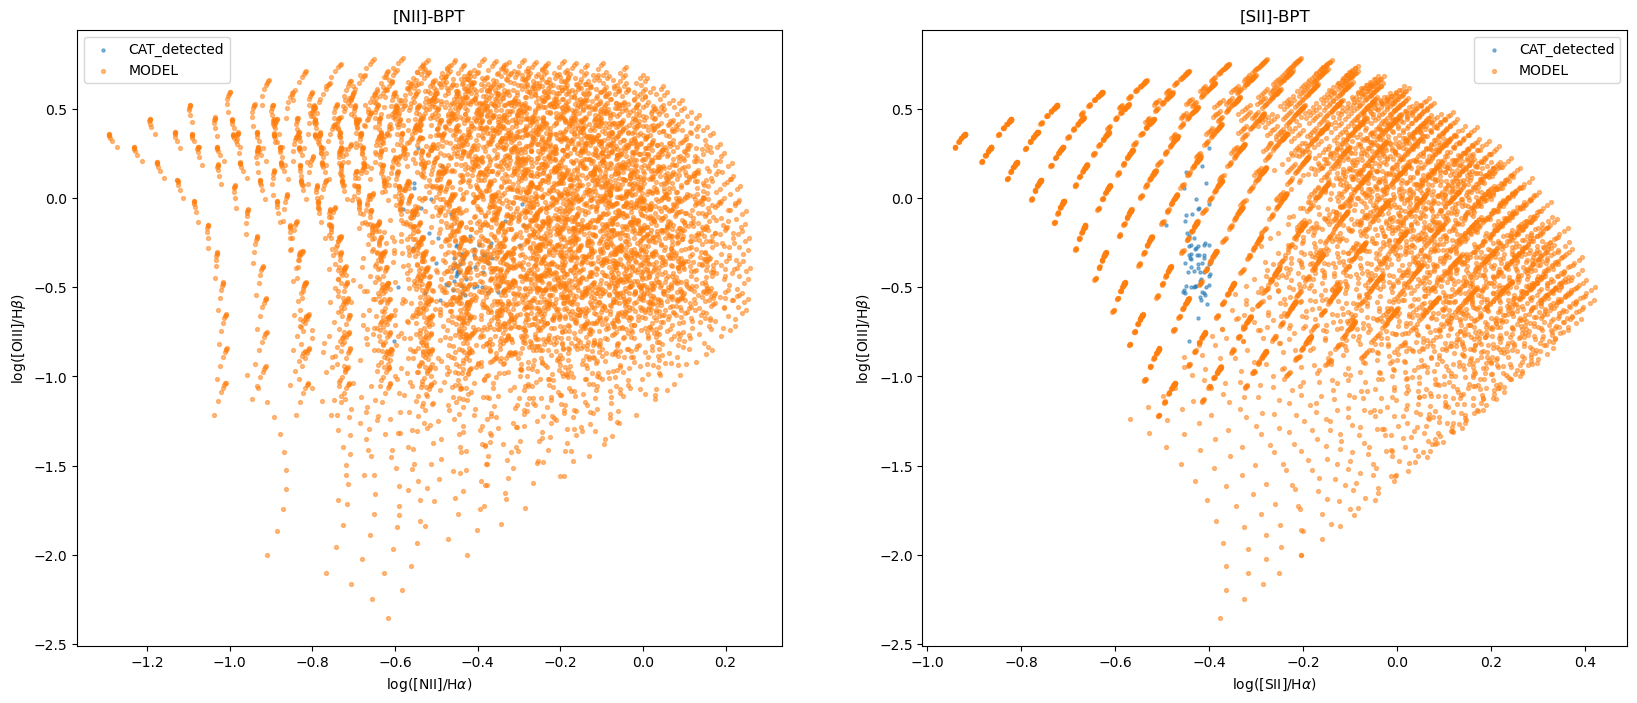

In [14]:
plt.figure(figsize=(20, 8))

# NII BPT
plt.subplot(1, 2, 1)
plt.scatter(DIG["log_nii_ha"], DIG["log_oiii_hb"], s=5, alpha=0.5, label="CAT_detected")
sub = model[model["class"] == "DIG"]
plt.scatter(sub["log_NII_Ha"],sub["log_OIII_Hb"],s=8,alpha=0.5, label='MODEL')
#plt.scatter(x_nii, y_oiii, label="NGC253", s=5, alpha=0.4)
plt.xlabel(r"log([NII]/H$\alpha$)")
plt.ylabel(r"log([OIII]/H$\beta$)")
plt.title("[NII]-BPT")
plt.legend()

# SII BPT
plt.subplot(1, 2, 2)
plt.scatter(DIG["log_sii_ha"], DIG["log_oiii_hb"], s=5, alpha=0.5, label="CAT_detected")
plt.scatter(sub["log_SII_Ha"],sub["log_OIII_Hb"],s=8,alpha=0.5, label='MODEL')
#plt.scatter(x_sii, y_oiii, label="NGC253", s=5, alpha=0.4)
plt.xlabel(r"log([SII]/H$\alpha$)")
plt.ylabel(r"log([OIII]/H$\beta$)")
plt.title("[SII]-BPT")
plt.legend()
plt.show()